# One Label, Different Air: Clustering Global Air-Pollution Profiles

ANLY 530 Machine Learning, Harrisburg University. KA1 project notebook. Author: Rama.

**Part A** (Steps 1 to 5) is the Week 10 exploratory clustering: data audit, scaling, k-means for k = 2 to 6, Ward clustering, cluster profiles and first stability checks.
**Part B** (Steps 6 to 8) follows peer feedback: rows with a missing pollutant, k = 2 versus k = 3, and cluster-wise stability.

Data: Global Air Pollution Dataset (Kaggle). On Kaggle, attach the dataset. Locally, save it as `data/global_air_pollution_dataset.csv`. Repository: https://github.com/rama17aneesh/Anly-air-pollution-profiles

---
# Part A. Exploratory clustering (Week 10)

*Original starter instructions:*

# ANLY 530 · Week 10 Kaggle Investigation
**Air-pollution profiles: clustering without labels**

Fork this notebook, attach the [Global Air Pollution Dataset](https://www.kaggle.com/datasets/hasibalmuzdadid/global-air-pollution-dataset), and complete all TODOs. Use AQI Category only for post hoc descriptive auditing, not training or selecting k. Seed: 42. This is an exploratory cross-sectional dataset, not a time series.

*Repository version. Kaggle notebook: https://www.kaggle.com/code/ramatum/week-10*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
SEED=42
files=list(Path("/kaggle/input").rglob("*.csv")) if Path("/kaggle/input").exists() else []
print("CSV files:", files[:10])

CSV files: []


## 1. Audit the data
**TODO: CODE** Locate the dataset CSV, inspect shape, missingness, duplicates, and descriptive statistics. Do not use `Overall AQI Value`, `AQI Category`, or dominant pollutant as clustering inputs.

In [2]:
FEATURES = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]

# Find the CSV: on Kaggle it is in /kaggle/input; locally put it in data/ (see README)
local = [Path("data/global_air_pollution_dataset.csv"), Path("../data/global_air_pollution_dataset.csv")]
csv_path = (next((f for f in files if "pollution" in f.name.lower()), files[0]) if files
            else next((p for p in local if p.exists()), local[0]))
df = pd.read_csv(csv_path)

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
assert all(f in df.columns for f in FEATURES), "A feature column is missing"

print("\nMissing values per column:")
print(df.isna().sum())

print("\nFully duplicated rows:", df.duplicated().sum())
print("Rows with identical pollutant scores (different cities):", df[FEATURES].duplicated().sum())

# Is the overall AQI just the highest of the four sub-indices? (why it is NOT a clustering input)
match = (df["AQI Value"] == df[FEATURES].max(axis=1)).mean()
print(f"\nOverall AQI equals the max sub-index in {match:.1%} of rows")

print("\nCities per country (top 5):")
print(df["Country"].value_counts().head(5))

display(df[FEATURES].describe().round(1))
print("Correlation between pollutant sub-indices:")
display(df[FEATURES].corr().round(2))

Shape (rows, columns): (23463, 12)

Columns: ['Country', 'City', 'AQI Value', 'AQI Category', 'CO AQI Value', 'CO AQI Category', 'Ozone AQI Value', 'Ozone AQI Category', 'NO2 AQI Value', 'NO2 AQI Category', 'PM2.5 AQI Value', 'PM2.5 AQI Category']

Missing values per column:
Country               427
City                    1
AQI Value               0
AQI Category            0
CO AQI Value            0
CO AQI Category         0
Ozone AQI Value         0
Ozone AQI Category      0
NO2 AQI Value           0
NO2 AQI Category        0
PM2.5 AQI Value         0
PM2.5 AQI Category      0
dtype: int64

Fully duplicated rows: 0
Rows with identical pollutant scores (different cities): 6363

Overall AQI equals the max sub-index in 99.4% of rows

Cities per country (top 5):
Country
United States of America    2872
India                       2488
Brazil                      1562
Germany                     1345
Russian Federation          1241
Name: count, dtype: int64


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
count,23463.0,23463.0,23463.0,23463.0
mean,1.4,35.2,3.1,68.5
std,1.8,28.1,5.3,54.8
min,0.0,0.0,0.0,0.0
25%,1.0,21.0,0.0,35.0
50%,1.0,31.0,1.0,54.0
75%,1.0,40.0,4.0,79.0
max,133.0,235.0,91.0,500.0


Correlation between pollutant sub-indices:


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
CO AQI Value,1.00,0.15,0.49,0.44
Ozone AQI Value,0.15,1.00,-0.18,0.34
NO2 AQI Value,0.49,-0.18,1.00,0.26
PM2.5 AQI Value,0.44,0.34,0.26,1.00


**INTERPRET (Step 1)**

The unit of observation is one city, with its 4 pollutants measured (CO, ozone, NO2 and PM2.5 AQI values). There are 23,463 cities from 175 countries. This is not a time series. It is a snapshot (cross-sectional), with each city recorded once. The dataset does not say when the pollutants were measured, and this matters for my analysis. Ozone is higher in the afternoon sun and NO2 rises in rush hour, and the cities are spread across countries and continents. When it is morning in the US, it is night in India. Two cities could fall into different clusters because of the local time of day, not because their air is really different.

The four pollutants are not comparable before scaling. They use the same AQI scale, but their spread is not even. PM2.5 has a standard deviation of about 55 and ozone about 28, while NO2 is about 5 and CO about 2. K-means groups cities by the distance between points and centroids, so without scaling the distances would be decided mostly by PM2.5 and ozone. CO and NO2 would barely count.

There are no missing values in the four pollutant columns (427 rows have no country name, which does not affect clustering). The overall AQI equals the highest sub-index in 99.4% of rows, so I keep the overall AQI and AQI Category out of the clustering. Using them would count the same information twice.

Two biases limit what I can claim. The first is coverage bias: the data only includes cities, and some countries (USA 2,872, India 2,488) have far more rows than others, so the groups may not generalize to rural areas or to new data. The second is timing bias, from the unknown date and different local times. The clusters describe this sample at one moment, not cities in general.

## 2. Scale and compare k-means solutions
**TODO: CODE** Complete the function, use complete-case data or justified imputation, and compare k=2,...,6 using a reproducible subsample for silhouette computation. Explain why k-means is sensitive to scaling.

   k  inertia_WCSS  sample_silhouette  WCSS_drop
0  2     67274.832              0.620        NaN
1  3     49490.247              0.615  17784.586
2  4     42438.782              0.561   7051.465
3  5     35666.535              0.518   6772.247
4  6     30696.412              0.492   4970.122


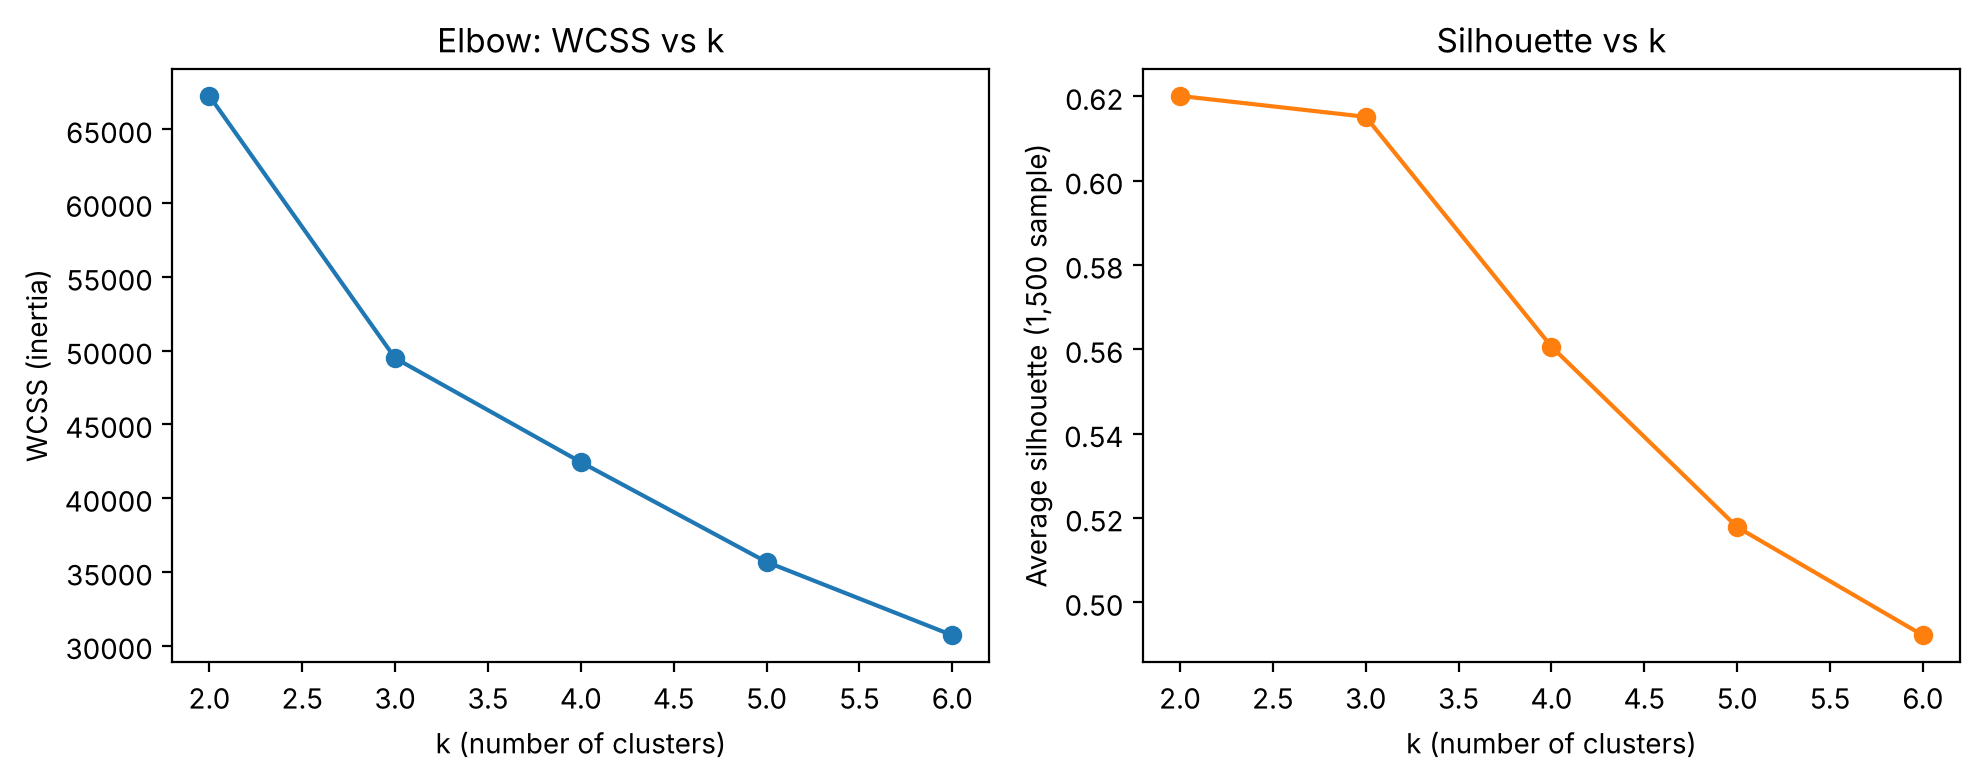

In [3]:
# Prepare: complete rows only (the audit showed no missing values in FEATURES)
X = df[FEATURES].dropna().copy()

# Scale: put all four pollutants on the same ruler (z-score)
Xs = StandardScaler().fit_transform(X)

# Fixed random sample of 1,500 cities for silhouette (silhouette on 23k rows is slow)
rng = np.random.default_rng(SEED)
idx = rng.choice(len(Xs), size=min(1500, len(Xs)), replace=False)

results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xs)
    sil = silhouette_score(Xs[idx], km.labels_[idx])
    results.append((k, km.inertia_, sil))

results = pd.DataFrame(results, columns=["k", "inertia_WCSS", "sample_silhouette"])
results["WCSS_drop"] = -results["inertia_WCSS"].diff()
print(results.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(results["k"], results["inertia_WCSS"], marker="o")
ax[0].set(title="Elbow: WCSS vs k", xlabel="k (number of clusters)", ylabel="WCSS (inertia)")
ax[1].plot(results["k"], results["sample_silhouette"], marker="o", color="tab:orange")
ax[1].set(title="Silhouette vs k", xlabel="k (number of clusters)", ylabel="Average silhouette (1,500 sample)")
plt.tight_layout(); plt.show()

**INTERPRET (Step 2)**

K-means is sensitive to scaling because it puts each city with its nearest centroid, and "nearest" is measured in raw numbers. A pollutant with a big spread (PM2.5) creates big distances and controls the grouping, so I standardize all four first.

The elbow method suggests the number of clusters, and I use the silhouette score as a second check on that choice. The elbow bends at k = 3, where the drop in WCSS slows from about 17,800 to about 7,000. The silhouette is highest at k = 2 (0.620), but k = 3 is almost the same (0.615). A gap of 0.005 is too small to choose k = 2 over k = 3, so I go with k = 3 and wait for the dendrogram and stability checks.

The highest silhouette does not prove the clusters are useful environmental or health groups. Silhouette is an internal check (internal validation). It measures how tight and well separated the clusters are, using the same data and distances that made them. It cannot tell us whether a cluster means a real risk.

The pollutants are interlinked. CO, NO2 and PM2.5 rise together (correlations 0.26 to 0.49) because they share sources: vehicle exhaust, power plants, industry, household heating and cooking with gas, coal or wood, crop and waste burning, and forest fires. Ozone is not released directly. It forms in sunlight from NO2 and other gases (VOCs), which is why it moves slightly opposite to NO2 (-0.18). When we burn fuel, we harm ourselves directly through the air we breathe and the atmosphere indirectly. Clusters with high pollutant scores signal higher health concern by AQI standards, but this dataset has no health outcomes, so the clusters alone cannot measure actual harm.

## 3. Hierarchical clustering
**TODO: CODE** Fit Ward hierarchical clustering on a fixed sample (e.g., 1,500 observations), compare with k-means on the *same sample*, and explain the meaning of a dendrogram. Avoid computing a full distance matrix for all rows.

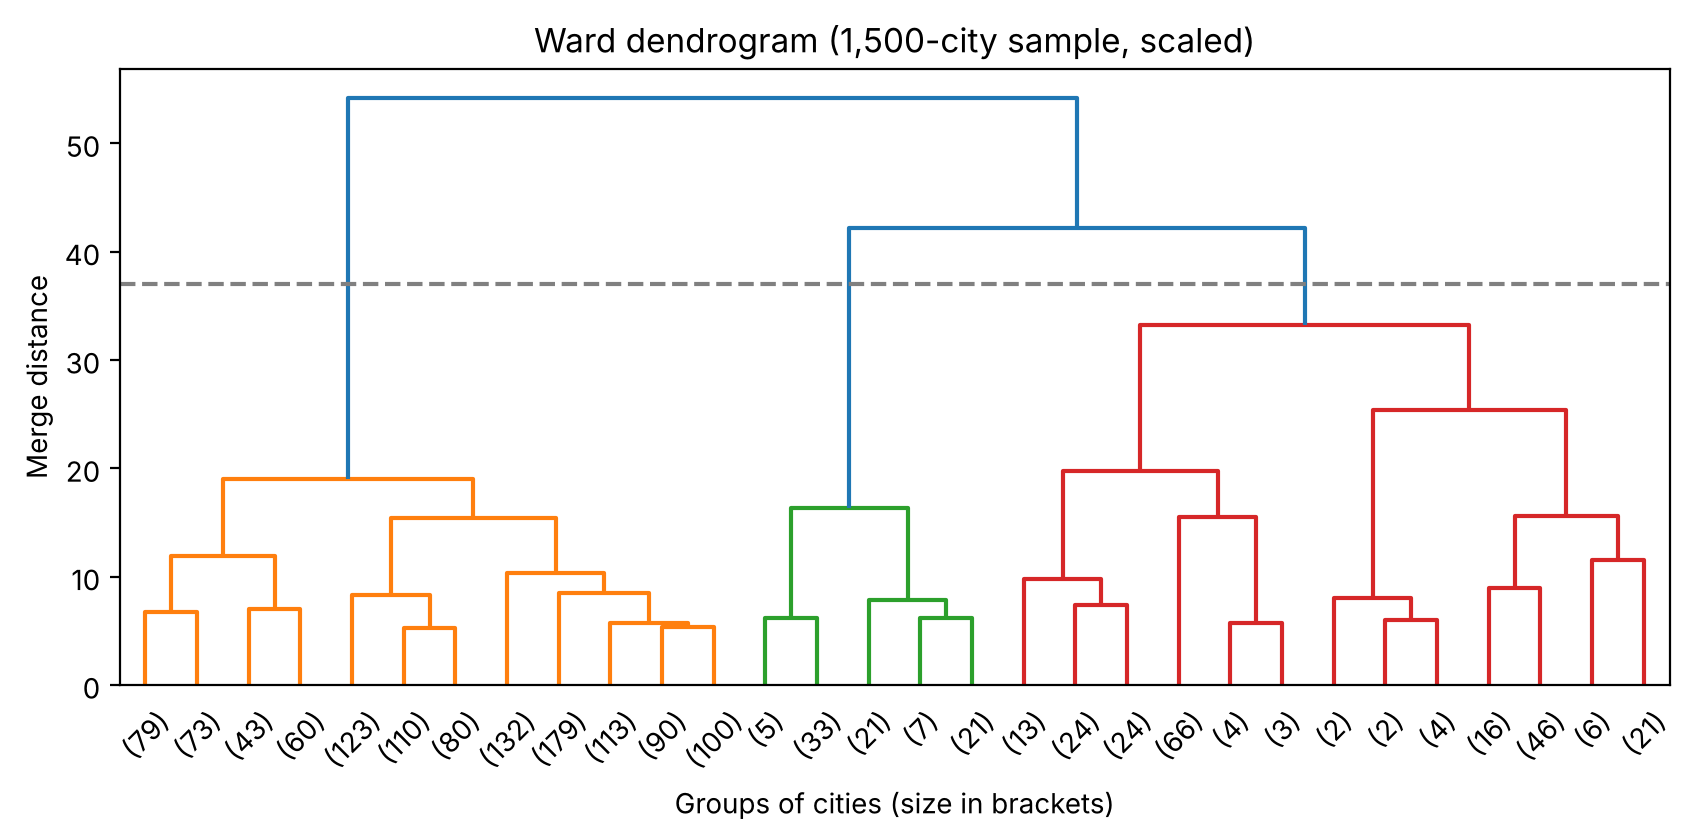

Heights of the last 6 merges: [19.  19.8 25.4 33.2 42.2 54.1]
   k  ARI_ward_vs_kmeans           ward_sizes          kmeans_sizes
0  2               0.701          [318, 1182]           [1271, 229]
1  3               0.705      [231, 1182, 87]       [151, 85, 1264]
2  4               0.833  [97, 134, 87, 1182]  [156, 68, 1138, 138]


,n,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,silhouette,negative_sil_%
cluster,,,,,,,
0,231,2.9,23.8,9.7,137.1,-0.034,54.1
1,1182,1.0,29.4,1.8,48.8,0.673,0.0
2,87,3.1,121.7,2.4,148.3,0.367,14.9


Overall Ward silhouette: 0.546


In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_samples

# Same fixed sample of 1,500 scaled cities as Step 2 (no full 23k x 23k distance matrix)
sample_X = Xs[idx]

# Dendrogram: the merge tree (Ward linkage)
Z = linkage(sample_X, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30)   # show only the last 30 merges so it is readable
plt.axhline(37, color="grey", linestyle="--")  # a cut between the 3rd and 2nd merges gives 3 groups
plt.title("Ward dendrogram (1,500-city sample, scaled)")
plt.xlabel("Groups of cities (size in brackets)"); plt.ylabel("Merge distance")
plt.show()
print("Heights of the last 6 merges:", np.round(Z[-6:, 2], 1))

# Ward vs k-means on the SAME sample, k = 2, 3, 4
rows = []
for k in [2, 3, 4]:
    ward_labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(sample_X)
    km_labels = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(sample_X)
    rows.append((k, adjusted_rand_score(ward_labels, km_labels),
                 np.bincount(ward_labels).tolist(), np.bincount(km_labels).tolist()))
print(pd.DataFrame(rows, columns=["k", "ARI_ward_vs_kmeans", "ward_sizes", "kmeans_sizes"]).round(3))

# The 3 Ward groups: average original AQI scores and silhouette per group
ward3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(sample_X)
w = X.iloc[idx].assign(cluster=ward3).groupby("cluster")[FEATURES].mean().round(1)
sil_w = pd.DataFrame({"cluster": ward3, "sil": silhouette_samples(sample_X, ward3)})
w.insert(0, "n", np.bincount(ward3))
w["silhouette"] = sil_w.groupby("cluster")["sil"].mean().round(3)
w["negative_sil_%"] = sil_w.groupby("cluster")["sil"].apply(lambda v: (v < 0).mean() * 100).round(1)
display(w)
print("Overall Ward silhouette:", round(sil_w["sil"].mean(), 3))

**INTERPRET (Step 3)**

Ward clustering starts with every city as its own group and keeps merging the two groups that add the least extra spread inside the group (WCSS). The dendrogram shows these merges as a tree. The height of each joining line is how different the two groups were when they merged, so a tall line means two groups that should stay apart. In my dendrogram the last two merges are at about 54 and 42, and then the heights drop to 33, 25 and 20. Cutting the tree at about 37 gives 3 branches, which supports k = 3.

Ward and k-means are two different methods, but both try to keep the spread inside clusters small. When they find similar groups (ARI 0.705 at k = 3), the groups are less likely to be an accident of one method. Agreement does not prove the groups are real or meaningful for health. Both methods use the same four scaled scores and the same idea of distance, so they share the same blind spots. If the scaling or the features are wrong, both will be wrong together.

Group size matters. The big group (1,182 of 1,500 cities) has a silhouette of 0.67, and it pulls the overall average up to 0.55. The PM2.5 and NO2 group (231 cities) has a silhouette of about 0, and more than half of its cities are closer to another group. A good overall silhouette can hide a weak cluster, so I check each cluster separately.

## 4. Profile and audit the clusters
**TODO: CODE** Produce a journal-style cluster profile table (n, mean pollutant sub-indices, silhouette). Optionally cross-tabulate AQI Category *after fitting* and discuss the risk of circular interpretation.

In [5]:
chosen_k = 3
labels = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10).fit_predict(Xs)

# Profile table: size, share, average AQI scores, silhouette per cluster
profile = X.assign(cluster=labels).groupby("cluster")[FEATURES].mean().round(1)
profile.insert(0, "n", np.bincount(labels))
profile.insert(1, "share_%", (np.bincount(labels) / len(labels) * 100).round(1))
s = pd.DataFrame({"cluster": labels[idx], "sil": silhouette_samples(Xs[idx], labels[idx])})
profile["silhouette"] = s.groupby("cluster")["sil"].mean().round(3)
profile["negative_sil_%"] = s.groupby("cluster")["sil"].apply(lambda v: (v < 0).mean() * 100).round(1)
display(profile)

# AFTER fitting only: compare clusters with AQI Category (description, not proof)
d = df.loc[X.index].assign(cluster=labels)
order = ["Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]
display(pd.crosstab(d["AQI Category"], d["cluster"]).reindex(order))

# Same label, different mix? Look only at "Moderate" cities
moderate = d[d["AQI Category"] == "Moderate"]
display(moderate.groupby("cluster")[FEATURES + ["AQI Value"]].mean().round(1)
        .assign(n=moderate["cluster"].value_counts().sort_index()))

# Which countries dominate each cluster? (coverage bias check)
display(d.groupby("cluster")["Country"].agg(lambda c: c.value_counts().head(4).to_dict()))

,n,share_%,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,silhouette,negative_sil_%
cluster,,,,,,,,
0,1768,7.5,4.3,16.4,17.1,123.4,0.241,13.1
1,20166,85.9,1.0,30.6,1.9,55.0,0.670,0.0
2,1529,6.5,2.7,117.8,2.3,184.0,0.328,13.5


cluster,0,1,2
AQI Category,,,
Good,9,9927,0
Moderate,725,8477,29
Unhealthy for Sensitive Groups,369,954,268
Unhealthy,574,779,874
Very Unhealthy,74,28,185
Hazardous,17,1,173


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,AQI Value,n
cluster,,,,,,
0,2.2,14.6,17.6,74.0,74.0,725
1,1.2,32.5,2.4,64.6,65.7,8477
2,2.6,90.2,1.8,86.1,93.3,29


cluster
0    {'United States of America': 678, 'India': 166...
1    {'United States of America': 2193, 'India': 15...
2    {'India': 794, 'China': 357, 'Pakistan': 184, ...
Name: Country, dtype: object

**INTERPRET (Step 4)**

Note: k-means cluster numbers can change between sklearn versions. I name the clusters by their profile, not by their number.

The three clusters, named by what the numbers show:

* **Lower, PM2.5-led profile** (20,166 cities, 86%). Low CO, NO2 and ozone, with moderate PM2.5 (about 55). This is the ordinary majority, and it is the tightest group (silhouette 0.67).
* **High PM2.5 with high NO2 and CO profile** (1,768 cities, 7.5%). NO2 is about 17 against about 2 in the majority, which points to burning and traffic sources. It is mostly USA and India. This is the weakest group (silhouette 0.24, 13% of cities closer to another group), so I name it with care.
* **High PM2.5 with high ozone profile** (1,529 cities, 6.5%). Ozone is about 118 and PM2.5 about 184. It is mostly India, China and Pakistan.

The clustering shows something the AQI label hides. Among the 9,231 "Moderate" cities, the 725 in the NO2 profile have about 7 times more NO2 than the Moderate cities in the majority profile (17.6 against 2.4), and most of them are in the USA. Same label, different pollution problem. "Unhealthy" cities are also spread across all three profiles.

I compared with AQI Category only after fitting. Almost all "Good" cities fall in the majority profile, but that is not a discovery. Low scores give a low AQI, which gives "Good", so it is the same numbers counted twice (circular).

These are pollution profiles, not health-risk groups. To call any of them a health-risk group I would need outside evidence: health outcomes such as asthma or hospital visits for the same cities, measurements repeated over time and seasons, traffic, industry and fire data to confirm the sources, and information on how each city was measured.

## 5. Stability and research decision
**TODO: CODE** Compare results under multiple seeds and a reasonable alternative scaling strategy. Quantify stability with ARI where observations match.

In [6]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

base = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit_predict(Xs)

# 1) Different random seeds (same data, same scaling)
seed_ari = {s: adjusted_rand_score(base, KMeans(n_clusters=3, random_state=s, n_init=10).fit_predict(Xs))
            for s in range(5)}
print("ARI vs seed 42, seeds 0-4:", {k: round(v, 3) for k, v in seed_ari.items()})

# 2) Fit on random 80% subsamples, assign ALL cities, compare (same cities matched)
sub_ari = []
for s in range(5):
    r = np.random.default_rng(s).choice(len(Xs), int(0.8 * len(Xs)), replace=False)
    km = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit(Xs[r])
    sub_ari.append(adjusted_rand_score(base, km.predict(Xs)))
print("ARI vs full fit, 80% subsamples:", np.round(sub_ari, 3))

# 3) Alternative scaling choices
rows = []
for name, Z_ in [("standard (chosen)", Xs),
                 ("robust (median/IQR)", RobustScaler().fit_transform(X)),
                 ("min-max (0 to 1)", MinMaxScaler().fit_transform(X)),
                 ("none (raw AQI)", X.values)]:
    lab = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit_predict(Z_)
    means = X.assign(c=lab).groupby("c")[FEATURES].mean().round(0).astype(int).values.tolist()
    rows.append((name, round(adjusted_rand_score(base, lab), 3), sorted(np.bincount(lab).tolist()), means))
display(pd.DataFrame(rows, columns=["scaling", "ARI_vs_standard", "cluster_sizes", "means [CO, O3, NO2, PM2.5]"]))

ARI vs seed 42, seeds 0-4: {0: 0.997, 1: 0.997, 2: 0.997, 3: 0.998, 4: 0.996}


ARI vs full fit, 80% subsamples: [0.98  0.981 0.976 0.983 0.989]


,scaling,ARI_vs_standard,cluster_sizes,"means [CO, O3, NO2, PM2.5]"
0,standard (chosen),1.000,"[1529, 1768, 20166]","[[4, 16, 17, 123], [1, 31, 2, 55], [3, 118, 2,..."
1,robust (median/IQR),0.921,"[1427, 1642, 20394]","[[5, 17, 17, 129], [1, 31, 2, 56], [3, 123, 2,..."
2,min-max (0 to 1),0.618,"[1145, 2924, 19394]","[[1, 30, 2, 49], [3, 138, 3, 156], [3, 31, 8, ..."
3,none (raw AQI),0.525,"[208, 3767, 19488]","[[1, 30, 3, 49], [3, 63, 5, 153], [4, 60, 5, 3..."


**INTERPRET (Step 5 and research decision)**

I recommend k-means with k = 3 on standardized pollutant sub-indices, reported as exploratory pollution profiles. The elbow bends at k = 3, and the silhouette (Rousseeuw, 1987) is almost tied between k = 2 (0.620) and k = 3 (0.615). Ward clustering on the same 1,500-city sample gave a three-branch dendrogram and agreed with k-means (ARI 0.705). The solution held across seeds 0 to 4 (ARI 0.996 or higher), across 80% subsamples (ARI 0.976 or higher), and under robust scaling (ARI 0.921). It changed without scaling (ARI 0.525), where PM2.5 alone sorted cities by severity, so the result depends on the scaling choice. The profiles are a lower PM2.5-led majority (86%), high PM2.5 with NO2 and CO (7.5%), and high PM2.5 with ozone (6.5%). Inside one label the difference shows: Moderate cities in the NO2 profile carry about seven times the NO2 of other Moderate cities. The NO2 profile is weak (silhouette 0.24), the data is one snapshot with unknown timing across time zones, and only cities are covered. Silhouette is internal validation (Jain, 2010), so these are not health-risk groups without outcome data. Seed 42 reproduces every number.

**References**

Itauma, I. (2026). *Machine learning using Python: Foundations, algorithms, applications, and reproducible research* (Version 2.0.0, 2nd ed., Chapter 11). Zenodo. https://doi.org/10.5281/zenodo.22136083

Jain, A. K. (2010). Data clustering: 50 years beyond K-means. *Pattern Recognition Letters, 31*(8), 651–666. https://doi.org/10.1016/j.patrec.2009.09.011

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

---
# Part B. Choosing k and checking cluster stability

Peer feedback on the Week 10 analysis asked (1) whether k = 3 adds useful information over k = 2 and (2) whether each cluster, especially the NO2-led profile, comes back when the data, seed or scaling changes. Part B answers both and checks rows where the overall AQI exceeds all four recorded sub-indices.

In [7]:
# Part B setup: reuse df, FEATURES, SEED and idx from Part A
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.metrics import silhouette_samples
pd.set_option("display.width", 160)
Xarr = df[FEATURES].to_numpy(dtype=float)       # array version of the four sub-indices
Xs = StandardScaler().fit_transform(Xarr)        # same standardized data as Part A
print(Xarr.shape, len(idx))

(23463, 4) 1500


## 6. Missing pollutants: rows where the overall AQI exceeds all four sub-indices

In [8]:
max4 = df[FEATURES].max(axis=1)
gap = df["AQI Value"] - max4
odd = df[gap != 0]
print("Rows where overall AQI != max of the four:", len(odd))
print("  overall higher:", (gap > 0).sum(), "| overall lower:", (gap < 0).sum())
print("\nCountries:"); print(odd["Country"].value_counts().head(5))
print("\nSize of the gap (AQI points):"); print(gap[gap != 0].describe().round(1))

Rows where overall AQI != max of the four: 141
  overall higher: 141 | overall lower: 0

Countries:
Country
India                               126
Pakistan                             10
Republic of Korea                     1
Uzbekistan                            1
Democratic Republic of the Congo      1
Name: count, dtype: int64

Size of the gap (AQI points):
count    141.0
mean      55.9
std       34.4
min        2.0
25%       29.0
50%       53.0
75%       76.0
max      166.0
dtype: float64


**INTERPRET.** In every mismatched row the overall AQI is higher than all four recorded sub-indices, and most of these rows are in India and Pakistan. A pollutant that is not in the file (likely PM10 or SO2) is setting the overall score there. The rows stay in the analysis because clustering uses only the four sub-indices, and the missing pollutants are reported as a limitation.

## 7. k = 2 versus k = 3, in original AQI units

In [9]:
def profile(labels):
    p = df[FEATURES].assign(cluster=labels).groupby("cluster").mean().round(1)
    p.insert(0, "n", np.bincount(labels))
    p.insert(1, "share_%", (np.bincount(labels) / len(labels) * 100).round(1))
    s = pd.Series(silhouette_samples(Xs[idx], labels[idx])).groupby(labels[idx]).mean()
    p["silhouette"] = s.round(3)
    return p

labels = {k: KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(Xs) for k in (2, 3)}
for k in (2, 3):
    print(f"k = {k}"); display(profile(labels[k]))

print("Where the k = 3 clusters come from (rows: k = 3, columns: k = 2)")
display(pd.crosstab(pd.Series(labels[3], name="k3"), pd.Series(labels[2], name="k2")))

k = 2


,n,share_%,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,silhouette
cluster,,,,,,,
0,20777,88.6,1.0,30.0,2.3,55.1,0.696
1,2686,11.4,3.9,75.3,8.7,172.6,0.016


k = 3


,n,share_%,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,silhouette
cluster,,,,,,,
0,1768,7.5,4.3,16.4,17.1,123.4,0.241
1,20166,85.9,1.0,30.6,1.9,55.0,0.670
2,1529,6.5,2.7,117.8,2.3,184.0,0.328


Where the k = 3 clusters come from (rows: k = 3, columns: k = 2)


k2,0,1
k3,,
0,740,1028
1,20000,166
2,37,1492


### Moderate cities under k = 2 and k = 3 (AQI Category used only after fitting)

In [10]:
moderate = (df["AQI Category"] == "Moderate").to_numpy()
for k in (2, 3):
    t = (df.loc[moderate, FEATURES].assign(cluster=labels[k][moderate])
         .groupby("cluster").mean().round(1))
    t["n"] = pd.Series(labels[k][moderate]).value_counts().sort_index()
    print(f"Moderate cities, k = {k}"); display(t)

Moderate cities, k = 2


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,n
cluster,,,,,
0,1.3,31.5,3.3,65.1,9075
1,2.9,21.2,22.8,85.4,156


Moderate cities, k = 3


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,n
cluster,,,,,
0,2.2,14.6,17.6,74.0,725
1,1.2,32.5,2.4,64.6,8477
2,2.6,90.2,1.8,86.1,29


**INTERPRET.** At k = 2 the polluted cities form one bin whose silhouette is close to zero (about 0.02). It averages NO2-led and ozone-led cities into in-between values that describe neither. At k = 3 that bin splits into two profiles that each fit better (silhouettes about 0.24 and 0.33). The NO2 profile takes about 1,000 cities from the k = 2 bin and about 740 from the k = 2 majority, which explains its fuzzy edge. Among Moderate cities, k = 3 separates 725 NO2-heavy cities and 29 ozone-heavy cities, while k = 2 separates only 156 and 0. The silhouette average is a tie, so k = 3 is chosen because it answers RQ1, not because of the score.

## 8. Cluster-wise stability (Hennig, 2007)

For each original cluster, the Jaccard similarity with the most similar cluster in a perturbed run is recorded (1 = same cities, 0 = no overlap). Common reading: 0.85 or more highly stable, 0.75 or more stable, 0.6 to 0.75 a pattern with doubtful membership, below 0.6 not to be trusted.

In [11]:
base = labels[3]
means = pd.DataFrame(Xarr, columns=FEATURES).groupby(base).mean()
def name_of(c):
    if means.loc[c, "NO2 AQI Value"] > 10: return "NO2-led"
    if means.loc[c, "Ozone AQI Value"] > 80: return "ozone-led"
    return "majority"
names = {c: name_of(c) for c in range(3)}

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)

def best_match(new_labels, points):
    out = {}
    for c in range(3):
        A = points[base[points] == c]
        out[names[c]] = max(jaccard(A, points[new_labels == d]) for d in np.unique(new_labels))
    return out

rows, everyone, n = [], np.arange(len(Xarr)), len(Xarr)
for s in range(10):
    lab = KMeans(n_clusters=3, random_state=s, n_init=10).fit_predict(Xs)
    rows.append({"test": "seed (10 runs)", **best_match(lab, everyone)})
rng = np.random.default_rng(0)
for b in range(50):
    r = np.unique(rng.choice(n, n, replace=True))
    sc = StandardScaler().fit(Xarr[r])
    km = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit(sc.transform(Xarr[r]))
    rows.append({"test": "bootstrap (50 runs)", **best_match(km.labels_, r)})
for b in range(20):
    r = np.sort(np.random.default_rng(100 + b).choice(n, int(0.8 * n), replace=False))
    km = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit(Xs[r])
    rows.append({"test": "80% subsample (20 runs)", **best_match(km.labels_, r)})

res = pd.DataFrame(rows)
cols = ["majority", "NO2-led", "ozone-led"]
display(res.groupby("test")[cols].agg(["mean", "min"]).round(3))

majority        NO2-led        ozone-led       
                            mean    min    mean    min      mean    min
test                                                                   
80% subsample (20 runs)    0.997  0.994   0.970  0.941     0.992  0.980
bootstrap (50 runs)        0.995  0.990   0.954  0.903     0.987  0.967
seed (10 runs)             0.999  0.999   0.994  0.992     0.998  0.991

### Stability under other scaling choices

,majority,NO2-led,ozone-led
scaling,,,
robust (median / IQR),0.982,0.854,0.913
min-max (0 to 1),0.902,0.321,0.735
none (raw AQI),0.884,0.193,0.328
log1p then standardize,0.515,0.372,0.180


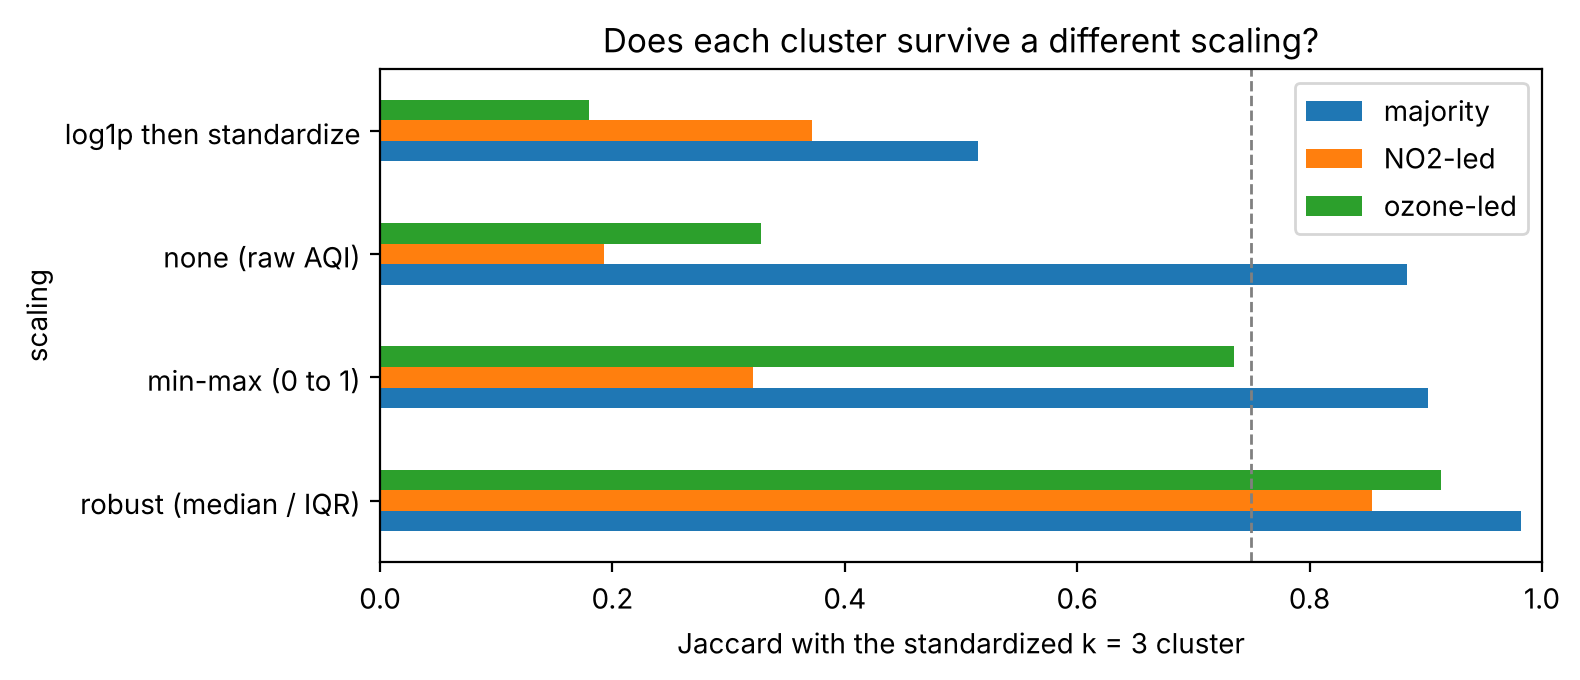

In [12]:
rows = []
for label, Z in [("robust (median / IQR)", RobustScaler().fit_transform(Xarr)),
                 ("min-max (0 to 1)", MinMaxScaler().fit_transform(Xarr)),
                 ("none (raw AQI)", Xarr),
                 ("log1p then standardize", StandardScaler().fit_transform(np.log1p(Xarr)))]:
    lab = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit_predict(Z)
    j = best_match(lab, everyone)
    rows.append({"scaling": label, **{c: round(j[c], 3) for c in cols}})
scal = pd.DataFrame(rows).set_index("scaling")
display(scal)

ax = scal.plot.barh(figsize=(8, 3.5))
ax.axvline(0.75, color="grey", linestyle="--", linewidth=1)
ax.set(xlabel="Jaccard with the standardized k = 3 cluster", xlim=(0, 1), title="Does each cluster survive a different scaling?")
plt.tight_layout(); plt.show()

**INTERPRET.** Every profile is highly stable when the data or seed changes (Jaccard above 0.90 in the worst run). The NO2-led profile also comes back under robust scaling (about 0.85), which, like standardization, weights each pollutant by its spread. It dissolves under min-max scaling, where extreme values (CO up to 133, PM2.5 capped at 500) squeeze ordinary NO2 differences, and without scaling, where PM2.5 dominates. The log transform reshapes the data and reshuffles all three clusters. The NO2 profile is repeatable but conditional on spread-based scaling, and that dependence is part of the answer to RQ2. Stability shows repeatability, not meaning (Hennig, 2007), so the chemistry check in the paper still matters.

**Reference.** Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis, 52*(1), 258–271. https://doi.org/10.1016/j.csda.2006.11.025

**AI-use statement**

I used Claude, an AI assistant, as a text and coding assistant.